# SWOT-OMIP demo: SSH wavenumber spectrum for one ocean box

**What this demo does.** The SWOT-OMIP intercomparison collects *pseudo-SWOT*
outputs: ocean-model sea-surface heights sampled along SWOT's orbit, with the
satellite's exact space-time sampling, resolution and KaRIn swath geometry. Comparing
model spectra against SWOT L3 observations — per region and per season — is how the
SWOT-OMIP seasonality paper diagnoses how well models reproduce the seasonal
variability of SSH at mesoscale and submesoscale wavelengths.

A wavenumber spectrum $P(k)$ of along-track SSH shows how sea-surface variance
distributes across spatial scales: the large-scale $k^{-2}$ (quasi-geostrophic
turbulence) range, steeper $k^{-3}$–$k^{-5}$ mesoscale-to-submesoscale transitions,
and the effective resolution floor of each model. Seasonal differences (e.g.
JFM vs JAS) expose the annual cycle of that variance.

In this notebook we compute **one** spectrum, for **one** 10°×10° box in the
Agulhas region (30–40°E, 30–40°S), from the **LLC4320** simulation, for the
**JFM** season, reading the pseudo-SWOT files directly from the public S3 mirror
(anonymous access — no credentials needed).

The production pipeline that computes this for *all* datasets, years, boxes and
seasons lives in
[contreras-m/SWOT-OMIP_postprocessing](https://github.com/contreras-m/SWOT-OMIP_postprocessing)
(`bin/compute_spectra.py`); this notebook replicates one chunk of it, transparently.

**Environment.** The compute chain needs `pyinterp` (Gauss-Seidel NaN filling),
available from conda-forge or as wheels on PyPI. With
[uv](https://docs.astral.sh/uv/):

```bash
uv venv .venv --python 3.12
uv pip install --python .venv s3fs xarray h5netcdf pyinterp geopandas pandas matplotlib watermark
```

In [1]:
DATASET = "LLC4320"
SPECTRA_KEY = "LLC4320"
SEASON = "JFM"
SEASON_MONTHS = [1, 2, 3]
START_DATE, END_DATE = "2024-01-01", "2024-03-31"

BOX_ID = 109  # Agulhas box: 30-40E, 30-40S (box indexing of mostly_ocean_boxes_filtered.geojson)

ENDPOINT = "https://s3-ige-ping.osug.fr"       # public ige-ping mirror (anonymous)
BASE = "ige/public/swot-omip/LLC4320"

# cycles of the SWOT reference calendar (2024) overlapping JFM (2024-01-01 .. 2024-03-31)
CYCLES = ["008", "009", "010", "011", "012", "013"]

# production spectrum for the same chunk, stored on DIVE (for comparison at the end)
REF_URL = ("https://minio.dive.edito.eu/project-meom-ige/OMIP/Global/LLC4320/"
           f"Global_box_{BOX_ID}_{SEASON}_{SPECTRA_KEY}.json")

OUTPUT = f"Global_box_{BOX_ID}_{SEASON}_{SPECTRA_KEY}.json" 

## 1. Access the pseudo-SWOT mirror

Each model contribution follows the protocol layout
`MODELNAME/cycle_XXX/MODELNAME_GRID_L3_LR_SSH_(cycle)_(pass)_(start)_(end)_v1.0.2.nc`:
one file per half-orbit pass, `ssh` on the KaRIn grid (`num_lines × num_pixels`).

In [2]:
import s3fs

fs = s3fs.S3FileSystem(anon=True, endpoint_url=ENDPOINT)
n_cycle8 = len(fs.glob(f"{BASE}/cycle_008/*.nc"))
sample = fs.glob(f"{BASE}/cycle_008/*.nc")[:2]
print(f"{n_cycle8} pass files in cycle_008; sample:")
for s in sample:
    print("  ", s.split('/')[-1])

88 pass files in cycle_008; sample:
   LLC4320_GRID_L3_LR_SSH_008_497_20240101T000706_20240101T005832_v1.0.2.nc
   LLC4320_GRID_L3_LR_SSH_008_498_20240101T005833_20240101T014959_v1.0.2.nc


## 2. Select only the satellite passes that matter for the box

KaRIn measures two 50-km swaths that cover only part of the globe on each pass.
Opening every file of every cycle just to discard most of them is wasteful, so we
first intersect the ground-track swaths with the box polygon. The box set and the
KaRIn swath geometries are the same files the paper processing uses.

A note on longitudes: the pseudo-SWOT files store `longitude` in the `[0, 360)`
convention, while the box/swath geometries are in `[-180, 180]` — a classic
dateline trap. We normalize the swath polygons to `[-180, 180]` and convert the
box bounds to `[0, 360)` for file subsetting.

In [3]:
import json
import urllib.request

import geopandas as gpd
from shapely.geometry import Polygon, shape

RAW = "https://raw.githubusercontent.com/contreras-m/SWOT-OMIP_postprocessing/main/data"

def normalize_lon_polygon(poly):
    if not isinstance(poly, Polygon):
        return poly
    shift = lambda coords: [((lon + 180) % 360 - 180, lat) for lon, lat in coords]
    return Polygon(shift(poly.exterior.coords), [shift(h.coords) for h in poly.interiors])

swath = gpd.read_file(f"{RAW}/KaRIn_2kms_science_geometries.geojson")
swath["geometry"] = swath["geometry"].apply(normalize_lon_polygon)
swath.crs = "EPSG:4326"

boxes = json.load(urllib.request.urlopen(f"{RAW}/mostly_ocean_boxes_filtered.geojson"))["features"]
box_poly = shape(boxes[BOX_ID]["geometry"])
lon_min, lat_min, lon_max, lat_max = box_poly.bounds
area = ((lon_min + 360) % 360, lat_min, (lon_max + 360) % 360, lat_max)
print(f"{len(boxes)} global boxes; box {BOX_ID}: lon {area[0]}-{area[2]}E, lat {area[1]}-{area[3]}")

pass_numbers = sorted({int(p) for p in swath[swath.intersects(box_poly)]["pass_number"]})
print(f"{len(pass_numbers)} KaRIn passes intersect box {BOX_ID}: {pass_numbers}")

/Users/lesommer/git/SWOT-OMIP/SWOT-OMIP_postprocessing/.venv/lib/python3.12/site-packages/pandas/core/generic.py:6448: FutureWarning: Overriding the CRS of a GeoDataFrame that already has CRS. This unsafe behavior will be deprecated in future versions. Use GeoDataFrame.set_crs method instead
  return object.__setattr__(self, name, value)


282 global boxes; box 109: lon 30.0-40.0E, lat -40.0--30.0
30 KaRIn passes intersect box 109: [40, 53, 68, 81, 96, 109, 124, 137, 152, 165, 180, 193, 209, 224, 237, 331, 346, 359, 374, 387, 402, 415, 430, 443, 458, 471, 486, 502, 515, 530]


## 3. List the matching pass files

Filenames carry cycle, pass and date
(`…_SSH_008_497_20240101T000706_20240101T005832_…`), so filtering is done on
names — no file is opened at this stage. The regex parser below accepts both the
protocol naming and the GEOMAR contributor variant (`…_eINALT100.nc`).

In [4]:
import re

FN = re.compile(r"_(\d{3})_(\d{3})_(\d{8}T\d{6})_(\d{8}T\d{6})[_.]")

def parse_pass_month(filename):
    m = FN.search(filename)
    if m is None:
        return None
    return int(m.group(2)), int(m.group(3)[4:6])   # pass number, month

files = []
for cyc in CYCLES:
    for f in fs.glob(f"{BASE}/cycle_{cyc}/*.nc"):
        info = parse_pass_month(f.split("/")[-1])
        if info is not None and info[0] in pass_numbers and info[1] in SEASON_MONTHS:
            files.append(f)

print(f"{len(files)} pass files selected for box {BOX_ID}, {SEASON}")
files[:2]

128 pass files selected for box 109, JFM


['ige/public/swot-omip/LLC4320/cycle_008/LLC4320_GRID_L3_LR_SSH_008_502_20240101T042420_20240101T051546_v1.0.2.nc',
 'ige/public/swot-omip/LLC4320/cycle_008/LLC4320_GRID_L3_LR_SSH_008_515_20240101T153309_20240101T162435_v1.0.2.nc']

## 4. Open the files and keep only the box

For each file we keep only the data inside the box. `ssh` is the modeled SSH
sampled on the KaRIn grid (`num_lines` along track, `num_pixels` across track).

In [5]:
import xarray as xr

datasets = {}
for i, f in enumerate(files):
    with fs.open(f, mode="rb") as fh:
        ds = xr.open_dataset(fh, engine="h5netcdf")
        ds = ds.drop_vars(["i_num_line", "i_num_pixel"], errors="ignore")
        selection = (
            (ds["longitude"] >= area[0]) & (ds["longitude"] <= area[2])
            & (ds["latitude"] >= area[1]) & (ds["latitude"] <= area[3])
        )
        if not selection.any():
            ds.close()
            continue
        ds = ds.where(selection, drop=True)
        if ds["latitude"].size == 0:
            ds.close()
            continue
        datasets[i] = ds

datasets = {i: ds for i, ds in enumerate(datasets.values())}   # contiguous keys, as in the production reader

print(f"{len(datasets)} pass files intersect box {BOX_ID}")

101 pass files intersect box 109


## 5. Fill the NaNs (Gauss-Seidel)

Land and the ~4-km nadir gap between the two KaRin swaths leave NaNs in the
`num_lines × num_pixels` grid. We fill them by Gauss-Seidel iteration on the 2-D
grid (as in the production chain): the two nadir-gap columns are masked *before*
filling (they contain no data at all) and columns that are entirely NaN are
restored afterwards. Filling lets the along-track columns form continuous
segments for the spectral estimate.

*API note:* pyinterp ≥ 2026 fills the array in place and returns
`(iterations, residual)`; the paper's production run used pyinterp 2025.11.0,
whose Gauss-Seidel returned `(converged, filled)`. The relaxation algorithm
itself is unchanged — the JSON records the exact pyinterp version used.

In [6]:
import numpy as np
import pyinterp
import pyinterp.fill as fill

def fill_nan(datasets, varname="ssh", num_threads=4):
    info = []
    out = {}
    for key in range(len(datasets)):
        values = np.asarray(datasets[key][varname].values, dtype="float64", order="C")
        if values.shape[1] >= 34:
            values[:, 33:35] = np.nan          # the nadir-gap columns (33, 34)
        nan_columns = np.all(np.isnan(values), axis=0)
        iterations, residual = fill.gauss_seidel(values, num_threads=num_threads)
        info.append((iterations, residual))
        values[:, nan_columns] = np.nan
        datasets[key][varname] = (("num_lines", "num_pixels"), values)
        out[key] = datasets[key]
    return info, out

print("pyinterp", pyinterp.__version__)
info, filled_datasets = fill_nan(datasets, varname="ssh")
print("Gauss-Seidel done for", len(info), "passes; (iterations, residual) e.g.:", info[:3])

pyinterp 2026.11.0


Gauss-Seidel done for 101 passes; (iterations, residual) e.g.: [(408, 9.941490470355419e-05), (2000, 0.00013605164208341236), (855, 9.985662002742757e-05)]


## 6. Segments, Welch spectra, and the box mean

Each across-track pixel column is one along-track *segment*. Contiguous
NaN-free segments longer than 120 points (~240 km at 2-km sampling) are Fourier
analysed with Welch ( Hann window, `nperseg = len(segment)`, no overlap, sampling
`fs = 0.5 cy/km` — i.e. 2 km posting). The box spectrum is the mean of the
per-segment PSDs at each wavenumber. Reference slopes $k^{-2}$ and $k^{-5}$ are
overlaid for orientation: quasi-geostrophic interior-turbulence spectra are
close to $k^{-2}$-ish over the mesoscale range, while smaller-scale motions
steepen towards $k^{-5}$.

In [7]:
import scipy.signal as signal

def retrieve_segments(datasets, varname="ssh"):
    segments = {}
    counter = 0
    for key in range(len(datasets)):
        for col in range(datasets[key].dims["num_pixels"]):
            ssh = datasets[key][varname].isel(num_pixels=col).values
            if np.any(~np.isnan(ssh)):
                seg = ssh[~np.isnan(ssh)]
                if not np.isnan(seg).any():
                    segments[counter] = seg
                    counter += 1
    return segments

def calculate_psd(segments, fs=0.5):
    psd_dict, freqs_dict = {}, {}
    counter = 0
    for seg in segments.values():
        if len(seg) > 120:
            freqs, psd = signal.welch(seg, fs=fs, nperseg=len(seg), noverlap=0)
            psd_dict[counter] = psd
            freqs_dict[counter] = freqs
            counter += 1
    return psd_dict, freqs_dict

def psd_mean_and_freq(psd_dict, freqs_dict):
    max_length = 0
    freqs_mean = None
    for k, array in psd_dict.items():
        if array.size > max_length:
            max_length = array.size
            freqs_mean = freqs_dict[k]
    psd_sum = np.zeros(max_length)
    psd_counts = np.zeros(max_length)
    for array in psd_dict.values():
        psd_sum[: array.size] += array
        psd_counts[: array.size] += 1
    return psd_sum / psd_counts, freqs_mean

segments = retrieve_segments(filled_datasets)
psd_dict, freqs_dict = calculate_psd(segments)
psd_mean, freqs_mean = psd_mean_and_freq(psd_dict, freqs_dict)
print(f"{len(segments)} segments, {len(psd_dict)} spectra; "
      f"wavenumbers {freqs_mean.min():.4g}..{freqs_mean.max():.4g} cy/km")

/var/folders/hl/9lpdpp7167v0gysd8hxnd_6w0000gn/T/ipykernel_77223/3826726561.py:7: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  for col in range(datasets[key].dims["num_pixels"]):


4408 segments, 4307 spectra; wavenumbers 0..0.25 cy/km


## 7. Store the spectrum (schema-compatible JSON)

The spectrum is written in the same JSON schema used by the paper's spectra store
(region/model/box bounds/season window/frequency and PSD arrays/machine traceability),
so downstream plotting code reads demo and production files identically.

In [8]:
import platform
from datetime import datetime

def packages_versions():
    try:
        from watermark import watermark
        return watermark(packages="numpy,xarray,s3fs,pyinterp")
    except Exception:
        import s3fs, xarray
        return f"numpy   : {np.__version__}\nxarray  : {xarray.__version__}\ns3fs    : {s3fs.__version__}\n"

document = {
    "region": f"Global/{SPECTRA_KEY}/Global_box_{BOX_ID}",
    "model": SPECTRA_KEY,
    "lon_min": area[0], "lon_max": area[2], "lat_min": area[1], "lat_max": area[3],
    "start_date": START_DATE, "end_date": END_DATE,
    "packages_versions": packages_versions(),
    "date_creation": datetime.now().isoformat(),
    "login_creator": platform.node(),
    "Frequency": [float(v) for v in freqs_mean],
    "Spectra": [float(v) for v in psd_mean],
    "machine_info": dict(platform.uname()._asdict()),
}

with open(OUTPUT, "w") as fh:
    json.dump(document, fh, indent=4)
print("wrote", OUTPUT)

wrote Global_box_109_JFM_LLC4320.json


## 8. Compare with the stored production spectrum

The production run (paper pipeline) already computed this chunk; it is stored on
the DIVE catalog. Overlapping the two is an honest end-to-end check of the demo —
small differences can arise from the exact cycle set and from NaN filling on the
box edges, but the curves should be on top of each other.

/var/folders/hl/9lpdpp7167v0gysd8hxnd_6w0000gn/T/ipykernel_77223/4085686896.py:19: RuntimeWarning: divide by zero encountered in divide
  sec = ax.secondary_xaxis("top", functions=(lambda x: 1 / x, lambda x: 1 / x))


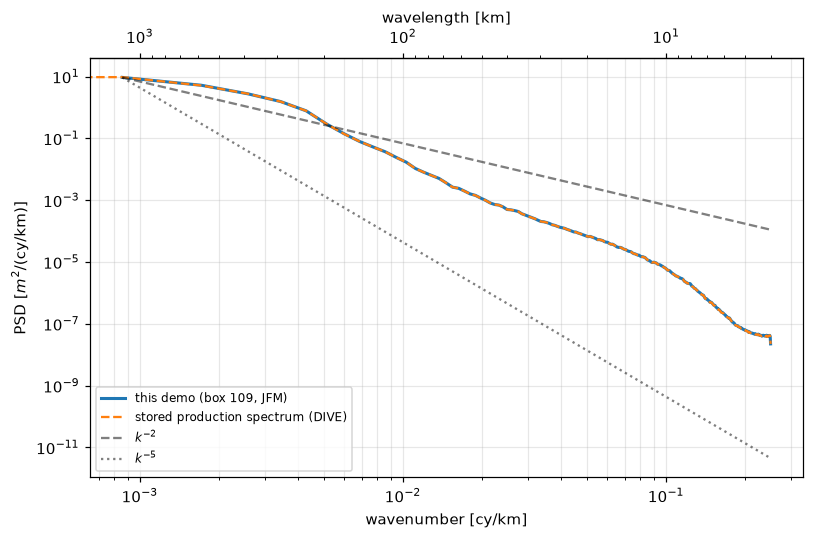

In [9]:
import matplotlib.pyplot as plt

ref = json.load(urllib.request.urlopen(REF_URL))

f = np.array(document["Frequency"])
p = np.array(document["Spectra"])
nz = f > 0

fig, ax = plt.subplots(figsize=(7.5, 5), dpi=110)
ax.loglog(f[nz], p[nz], lw=2, label=f"this demo (box {BOX_ID}, JFM)")
ax.loglog(np.array(ref["Frequency"]), np.array(ref["Spectra"]), "--", lw=1.5,
          label="stored production spectrum (DIVE)")
ax.loglog(f[nz], p[nz][0] * (f[nz] / f[nz][0]) ** -2, "k--", alpha=0.5, label=r"$k^{-2}$")
ax.loglog(f[nz], p[nz][0] * (f[nz] / f[nz][0]) ** -5, "k:", alpha=0.5, label=r"$k^{-5}$")
ax.set_xlabel("wavenumber [cy/km]")
ax.set_ylabel("PSD [$m^2$/(cy/km)]")
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc="lower left", fontsize=8)
sec = ax.secondary_xaxis("top", functions=(lambda x: 1 / x, lambda x: 1 / x))
sec.set_xlabel("wavelength [km]")
fig.tight_layout()
plt.show()

In [10]:
if np.array(ref["Frequency"]).shape == f.shape and np.allclose(np.array(ref["Frequency"]), f):
    rel = np.abs(p[1:] - np.array(ref["Spectra"])[1:]) / np.abs(np.array(ref["Spectra"])[1:])
    print(f"same wavenumber grid; median relative difference: {np.median(rel):.2%}")
else:
    print("wavenumber grids differ (longest segment differs); compare the curves qualitatively")

same wavenumber grid; median relative difference: 0.49%


## Where to go next

- **All datasets / all boxes / all seasons:** the parameterized pipeline
  `bin/compute_spectra.py` in
  [SWOT-OMIP_postprocessing](https://github.com/contreras-m/SWOT-OMIP_postprocessing)
  runs this exact chain chunk-by-chunk (`dataset × year × box × season`), reads
  each dataset from its registered S3 endpoint or a local mirror, skips
  already-computed spectra, and writes to the spectra store.
- **Other mirrors/datasets:** endpoints of all contributions are registered in the
  [swot-omip protocol repo](https://github.com/IGE-OPERA/swot-omip) dataset YAMLs.
- **The paper:** figures comparing model-vs-SWOT seasonal spectra for the full
  global box set are generated from the stored spectra by the plot notebooks in
  the postprocessing repo.